In [1]:
import torch
import torch.nn as nn
import numpy as np

In [2]:
# fake example input data for ANN 

wt_emb = torch.randn(480)
mut_emb = torch.randn(480)

ann_input = torch.cat((wt_emb, mut_emb)) #  x = [eWT, eMUT] 
print(mut_emb.shape)
print(wt_emb.shape )
print(ann_input.shape)

torch.Size([480])
torch.Size([480])
torch.Size([960])


In [3]:

# building NN model by stacking layers in a specific order 
model = nn.Sequential(
    nn.Linear(960, 128), # first layer, 960 input features, 128 neurons 
    nn.ReLU(), # activation function, (-)ve = 0, (+)ve = (+)ve ;; sigmoid also exists where (-) < 0.5, and (+) > 0.5 ;; dropout 
    nn.Linear(128, 64), # second layer, 128 input features, 64 neurons
    nn.ReLU(),
    nn.Linear(64, 1) # third layer, 64 input features, 1 neuron
    # the output will be a single number which will be converted into a probability between 0 and 1 using a sigmoid function
    # near 0 = mutation does not weaken, near 1 = mutation weakens  
)

print(model)


Sequential(
  (0): Linear(in_features=960, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)


In [4]:
output = model(ann_input)
probability = torch.sigmoid(output)
print(output.item())
print(probability.item())

0.1002039983868599
0.5250300765037537


In [5]:

from transformers import AutoTokenizer, AutoModel

model_name = "facebook/esm2_t12_35M_UR50D"

tokenizer = AutoTokenizer.from_pretrained(model_name)
esm_model = AutoModel.from_pretrained(model_name)

esm_model.eval()



/opt/miniconda3/envs/esm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/miniconda3/envs/esm/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t12_35M_UR50D and are newly initialized: ['esm.pooler.dense.bias', 'esm.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


EsmModel(
  (embeddings): EsmEmbeddings(
    (word_embeddings): Embedding(33, 480, padding_idx=1)
    (dropout): Dropout(p=0.0, inplace=False)
    (position_embeddings): Embedding(1026, 480, padding_idx=1)
  )
  (encoder): EsmEncoder(
    (layer): ModuleList(
      (0-11): 12 x EsmLayer(
        (attention): EsmAttention(
          (self): EsmSelfAttention(
            (query): Linear(in_features=480, out_features=480, bias=True)
            (key): Linear(in_features=480, out_features=480, bias=True)
            (value): Linear(in_features=480, out_features=480, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (rotary_embeddings): RotaryEmbedding()
          )
          (output): EsmSelfOutput(
            (dense): Linear(in_features=480, out_features=480, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (LayerNorm): LayerNorm((480,), eps=1e-05, elementwise_affine=True)
        )
        (intermediate): EsmIntermediate(
  

In [6]:
#  example 

wt_sequence = "MKTAYIAKQRQISFVKSHFSRQ"
mutation_position = 5  
mutant_aa = "V"

mut_sequence = (
    wt_sequence[:mutation_position - 1]
    + mutant_aa
    + wt_sequence[mutation_position:]
)

print("Wild-type:", wt_sequence)
print("Mutant:   ", mut_sequence)
print("Original amino acid:", wt_sequence[mutation_position - 1])
print("Mutant amino acid:", mut_sequence[mutation_position - 1])


Wild-type: MKTAYIAKQRQISFVKSHFSRQ
Mutant:    MKTAVIAKQRQISFVKSHFSRQ
Original amino acid: Y
Mutant amino acid: V


In [7]:

# Convert amino acid sequences into tokens
wt_tokens = tokenizer(wt_sequence, return_tensors="pt")
mut_tokens = tokenizer(mut_sequence, return_tensors="pt")

# Generate embeddings without computing gradients
with torch.no_grad():
    wt_output = esm_model(**wt_tokens)
    mut_output = esm_model(**mut_tokens)

# Extract embeddings for all token positions
wt_embeddings = wt_output.last_hidden_state
mut_embeddings = mut_output.last_hidden_state

print("WT embedding shape:", wt_embeddings.shape)
print("Mutant embedding shape:", mut_embeddings.shape)


WT embedding shape: torch.Size([1, 24, 480])
Mutant embedding shape: torch.Size([1, 24, 480])


In [8]:

# extracting embeddings for position 5 which is the mutation position 

wt_mutation_embedding = wt_embeddings[0, mutation_position, :]
mut_mutation_embedding = mut_embeddings[0, mutation_position, :]

print("WT residue embedding:", wt_mutation_embedding.shape)
print("Mutant residue embedding:", mut_mutation_embedding.shape)


WT residue embedding: torch.Size([480])
Mutant residue embedding: torch.Size([480])


In [9]:

# Combine WT and mutant residue embeddings
real_ann_input = torch.cat(
    (wt_mutation_embedding, mut_mutation_embedding)
)

print("ANN input shape:", real_ann_input.shape)

# Pass the embeddings through our ANN
with torch.no_grad():
    logit = model(real_ann_input)
    probability = torch.sigmoid(logit)

print("Raw ANN output:", logit.item())
print("Probability of weaker binding:", probability.item())


ANN input shape: torch.Size([960])
Raw ANN output: 0.044486843049526215
Probability of weaker binding: 0.5111199021339417


In [10]:
import pandas as pd
df = pd.read_csv("skempi_with_seq.csv")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

,#Pdb,Mutation(s)_cleaned,ddG,n_meas,ddG_min,ddG_max,wt,chain,pos,icode,mt,mut_location,ambiguous,label_binary,pdb_id,status,seq,seq_idx
0,1A22_A_B,CA171A,1.018850,1,1.018850,1.018850,C,A,171,NaN,A,COR,False,1,1A22,ok,FPTIPLSRLFDNAMLRAHRLHQLAFDTYQEFEEAYIPKEQKYSFLQ...,170
1,1A22_A_B,CB67A,0.000000,1,0.000000,0.000000,C,B,67,NaN,A,SUP,False,0,1A22,ok,PKFTKCRSPERETFSCHWTLGPIQLFYTRRNTQEWTQEWKECPDYV...,66
2,1A22_A_B,CB81A,0.000000,1,0.000000,0.000000,C,B,81,NaN,A,COR,False,0,1A22,ok,PKFTKCRSPERETFSCHWTLGPIQLFYTRRNTQEWTQEWKECPDYV...,80
3,1A22_A_B,DA160A,0.973834,2,0.790489,1.157179,D,A,160,NaN,A,COR,False,1,1A22,ok,FPTIPLSRLFDNAMLRAHRLHQLAFDTYQEFEEAYIPKEQKYSFLQ...,159
4,1A22_A_B,DA26A,-0.211197,1,-0.211197,-0.211197,D,A,26,NaN,A,SUR,False,0,1A22,ok,FPTIPLSRLFDNAMLRAHRLHQLAFDTYQEFEEAYIPKEQKYSFLQ...,25



Column names:
['#Pdb', 'Mutation(s)_cleaned', 'ddG', 'n_meas', 'ddG_min', 'ddG_max', 'wt', 'chain', 'pos', 'icode', 'mt', 'mut_location', 'ambiguous', 'label_binary', 'pdb_id', 'status', 'seq', 'seq_idx']


In [11]:

# Keep rows with successful sequence mapping
df_valid = df[df["status"] == "ok"].copy()

# Remove rows missing essential information
df_valid = df_valid.dropna(
    subset=["seq", "seq_idx", "wt", "mt", "label_binary"]
)

# Convert mutation indices into integers
df_valid["seq_idx"] = df_valid["seq_idx"].astype(int)

# Check that each mutation position matches the WT residue
def check_mutation(row):
    sequence = row["seq"]
    index = row["seq_idx"]

    if index < 0 or index >= len(sequence):
        return False

    return sequence[index] == row["wt"]

df_valid["mutation_valid"] = df_valid.apply(
    check_mutation, axis=1
)

print("Total rows:", len(df))
print("Successfully mapped rows:", len(df_valid))
print("Valid mutations:", df_valid["mutation_valid"].sum())
print("Invalid mutations:", (~df_valid["mutation_valid"]).sum())


Total rows: 4191
Successfully mapped rows: 4191
Valid mutations: 4191
Invalid mutations: 0


In [12]:

# Calculate sequence lengths
df_valid["seq_length"] = df_valid["seq"].str.len()

# Check sequence lengths
print("Shortest sequence:", df_valid["seq_length"].min())
print("Longest sequence:", df_valid["seq_length"].max())

# Count sequences that exceed ESM-2's limit
too_long = (df_valid["seq_length"] > 1022).sum()

print("Sequences exceeding 1022 residues:", too_long)

# Check our experimental labels
print("\nLabel distribution:")
print(df_valid["label_binary"].value_counts())

# Check ambiguous measurements
print("\nAmbiguous mutations:")
print(df_valid["ambiguous"].value_counts(dropna=False))


Shortest sequence: 5
Longest sequence: 1267
Sequences exceeding 1022 residues: 39

Label distribution:
label_binary
1    3151
0    1040
Name: count, dtype: int64

Ambiguous mutations:
ambiguous
False    4084
True      107
Name: count, dtype: int64


In [13]:

# Keep sequences within ESM-2's length limit
df_filtered = df_valid[
    df_valid["seq_length"] <= 1022
].copy()

# Remove ambiguous experimental measurements
df_filtered = df_filtered[
    df_filtered["ambiguous"] == False
].copy()

# Reset row indices
df_filtered = df_filtered.reset_index(drop=True)

print("Original mutations:", len(df_valid))
print("Remaining mutations:", len(df_filtered))

print("\nFinal label distribution:")
print(df_filtered["label_binary"].value_counts())

print("\nUnique protein complexes:")
print(df_filtered["pdb_id"].nunique())


Original mutations: 4191
Remaining mutations: 4046

Final label distribution:
label_binary
1    3043
0    1003
Name: count, dtype: int64

Unique protein complexes:
314


In [14]:

from sklearn.model_selection import GroupShuffleSplit

# First split: 70% training, 30% remaining
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        df_filtered,
        groups=df_filtered["pdb_id"]
    )
)

train_df = df_filtered.iloc[train_idx].copy()
temp_df = df_filtered.iloc[temp_idx].copy()

# Second split: divide remaining data into validation/test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        groups=temp_df["pdb_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("Training mutations:", len(train_df))
print("Validation mutations:", len(val_df))
print("Testing mutations:", len(test_df))


Training mutations: 2536
Validation mutations: 888
Testing mutations: 622


In [15]:

# Get unique PDB complexes in each set
train_pdbs = set(train_df["pdb_id"])
val_pdbs = set(val_df["pdb_id"])
test_pdbs = set(test_df["pdb_id"])

# Check whether any PDB complexes overlap
print("Train/Val overlap:", len(train_pdbs & val_pdbs))
print("Train/Test overlap:", len(train_pdbs & test_pdbs))
print("Val/Test overlap:", len(val_pdbs & test_pdbs))

# Check class distribution
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(data)} mutations")
    print(data["label_binary"].value_counts())
    print("Positive fraction:", data["label_binary"].mean())


Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0

Training: 2536 mutations
label_binary
1    1927
0     609
Name: count, dtype: int64
Positive fraction: 0.7598580441640379

Validation: 888 mutations
label_binary
1    687
0    201
Name: count, dtype: int64
Positive fraction: 0.7736486486486487

Testing: 622 mutations
label_binary
1    429
0    193
Name: count, dtype: int64
Positive fraction: 0.6897106109324759


In [16]:

# Select the first mutation from our training dataset
example = train_df.iloc[0]

# Extract its information
wt_sequence = example["seq"]
mutation_idx = int(example["seq_idx"])
wt_aa = example["wt"]
mut_aa = example["mt"]

# Construct the mutant sequence
mut_sequence = (
    wt_sequence[:mutation_idx]
    + mut_aa
    + wt_sequence[mutation_idx + 1:]
)

print("PDB:", example["pdb_id"])
print("Mutation:", wt_aa, "→", mut_aa)
print("Sequence index:", mutation_idx)
print("WT residue:", wt_sequence[mutation_idx])
print("Mutant residue:", mut_sequence[mutation_idx])
print("Experimental ddG:", example["ddG"])
print("Actual label:", example["label_binary"])


PDB: 1A22
Mutation: C → A
Sequence index: 170
WT residue: C
Mutant residue: A
Experimental ddG: 1.0188496237532307
Actual label: 1


In [17]:

# Tokenize both sequences
wt_tokens = tokenizer(wt_sequence, return_tensors="pt")
mut_tokens = tokenizer(mut_sequence, return_tensors="pt")

# Generate embeddings using pretrained ESM-2
with torch.no_grad():
    wt_output = esm_model(**wt_tokens)
    mut_output = esm_model(**mut_tokens)

# Extract the residue embeddings
# +1 accounts for ESM-2's beginning-of-sequence token
wt_embedding = wt_output.last_hidden_state[
    0, mutation_idx + 1, :
]

mut_embedding = mut_output.last_hidden_state[
    0, mutation_idx + 1, :
]

# Concatenate the embeddings
ann_features = torch.cat(
    (wt_embedding, mut_embedding)
)

print("WT embedding shape:", wt_embedding.shape)
print("Mutant embedding shape:", mut_embedding.shape)
print("Combined ANN input:", ann_features.shape)


WT embedding shape: torch.Size([480])
Mutant embedding shape: torch.Size([480])
Combined ANN input: torch.Size([960])


In [18]:

def extract_mutation_embedding(row):

    # Get mutation information
    sequence = row["seq"]
    idx = int(row["seq_idx"])
    mutant_aa = row["mt"]

    # Construct mutant sequence
    mutant_sequence = (
        sequence[:idx]
        + mutant_aa
        + sequence[idx + 1:]
    )

    # Tokenize both sequences
    wt_tokens = tokenizer(sequence, return_tensors="pt")
    mut_tokens = tokenizer(mutant_sequence, return_tensors="pt")

    # Generate ESM-2 embeddings
    with torch.no_grad():
        wt_output = esm_model(**wt_tokens)
        mut_output = esm_model(**mut_tokens)

    # Extract embeddings at the mutated position
    wt_embedding = wt_output.last_hidden_state[0, idx + 1, :]
    mut_embedding = mut_output.last_hidden_state[0, idx + 1, :]

    # Combine WT and mutant embeddings
    combined = torch.cat(
        (wt_embedding, mut_embedding)
    )

    return combined


In [19]:
# Select our first training mutation
example = train_df.iloc[0]

# Extract its embeddings using our function
features = extract_mutation_embedding(example)

# Check the output
print("Feature shape:", features.shape)
print("First 10 features:", features[:10])
print("Experimental label:", example["label_binary"])


Feature shape: torch.Size([960])
First 10 features: tensor([-0.0713,  0.2966,  0.2683, -0.0665, -0.2470, -0.0680, -0.3358, -0.0365,
         0.2905, -0.2121])
Experimental label: 1


In [20]:

# Store previously calculated WT embeddings
wt_cache = {}

def extract_embedding_cached(row):

    sequence = row["seq"]
    idx = int(row["seq_idx"])
    mutant_aa = row["mt"]

    # Check whether WT sequence has already been processed
    if sequence not in wt_cache:

        tokens = tokenizer(sequence, return_tensors="pt")

        with torch.no_grad():
            output = esm_model(**tokens)

        wt_cache[sequence] = output.last_hidden_state[0].cpu()

    # Retrieve WT embedding from cache
    wt_embedding = wt_cache[sequence][idx + 1, :]

    # Construct mutant sequence
    mutant_sequence = (
        sequence[:idx]
        + mutant_aa
        + sequence[idx + 1:]
    )

    # Generate mutant embedding
    mut_tokens = tokenizer(mutant_sequence, return_tensors="pt")

    with torch.no_grad():
        mut_output = esm_model(**mut_tokens)

    mut_embedding = mut_output.last_hidden_state[0, idx + 1, :].cpu()

    # Combine both embeddings
    combined = torch.cat((wt_embedding, mut_embedding))

    return combined


In [21]:

# Use the first two training mutations
example1 = train_df.iloc[0]
example2 = train_df.iloc[1]

# Extract their features
features1 = extract_embedding_cached(example1)
features2 = extract_embedding_cached(example2)

print("First mutation shape:", features1.shape)
print("Second mutation shape:", features2.shape)

print("Number of cached WT sequences:", len(wt_cache))


First mutation shape: torch.Size([960])
Second mutation shape: torch.Size([960])
Number of cached WT sequences: 2


In [22]:

# Count unique wild-type sequences
unique_sequences = df_filtered["seq"].nunique()

print("Total mutations:", len(df_filtered))
print("Unique wild-type sequences:", unique_sequences)

# Estimate memory needed for caching
total_residues = (
    df_filtered[["seq"]]
    .drop_duplicates()["seq"]
    .str.len()
    .sum()
)

# Each ESM-2 embedding contains 480 float32 values
estimated_mb = total_residues * 480 * 4 / (1024 ** 2)

print(f"Estimated WT cache memory: {estimated_mb:.2f} MB")


Total mutations: 4046
Unique wild-type sequences: 411
Estimated WT cache memory: 135.02 MB


In [23]:

def create_feature_matrix(data):

    feature_list = []
    label_list = []

    for i, (_, row) in enumerate(data.iterrows()):

        # Generate features for one mutation
        features = extract_embedding_cached(row)

        # Store the features
        feature_list.append(features)

        # Store its experimental label
        label_list.append(float(row["label_binary"]))

        # Display progress every 100 mutations
        if (i + 1) % 100 == 0:
            print(f"Processed {i + 1}/{len(data)} mutations")

    # Combine feature vectors into one matrix
    X = torch.stack(feature_list)

    # Convert labels into a column tensor
    y = torch.tensor(
        label_list,
        dtype=torch.float32
    ).unsqueeze(1)

    return X, y


In [24]:

# Test on five training mutations
small_sample = train_df.head(5)

X_small, y_small = create_feature_matrix(small_sample)

print("Feature matrix shape:", X_small.shape)
print("Label tensor shape:", y_small.shape)
print("Labels:", y_small.squeeze().tolist())


Feature matrix shape: torch.Size([5, 960])
Label tensor shape: torch.Size([5, 1])
Labels: [1.0, 0.0, 0.0, 1.0, 0.0]


In [25]:

# Ensure ESM-2 remains in evaluation mode
esm_model.eval()

print("Generating training embeddings...")
X_train, y_train = create_feature_matrix(train_df)

print("Generating validation embeddings...")
X_val, y_val = create_feature_matrix(val_df)

print("Generating testing embeddings...")
X_test, y_test = create_feature_matrix(test_df)

print("\nFinal shapes:")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Generating training embeddings...
Processed 100/2536 mutations
Processed 200/2536 mutations
Processed 300/2536 mutations
Processed 400/2536 mutations
Processed 500/2536 mutations
Processed 600/2536 mutations
Processed 700/2536 mutations
Processed 800/2536 mutations
Processed 900/2536 mutations
Processed 1000/2536 mutations
Processed 1100/2536 mutations
Processed 1200/2536 mutations
Processed 1300/2536 mutations
Processed 1400/2536 mutations
Processed 1500/2536 mutations
Processed 1600/2536 mutations
Processed 1700/2536 mutations
Processed 1800/2536 mutations
Processed 1900/2536 mutations
Processed 2000/2536 mutations
Processed 2100/2536 mutations
Processed 2200/2536 mutations
Processed 2300/2536 mutations
Processed 2400/2536 mutations
Processed 2500/2536 mutations
Generating validation embeddings...
Processed 100/888 mutations
Processed 200/888 mutations
Processed 300/888 mutations
Processed 400/888 mutations
Processed 500/888 mutations
Processed 600/888 mutations
Processed 700/888 mut

In [26]:

torch.save(
    {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test
    },
    "skempi_esm2_features.pt"
)

print("Feature matrices saved successfully!")


Feature matrices saved successfully!


In [27]:
model = nn.Sequential(
    nn.Linear(960, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

In [28]:

# Calculate class counts in the training dataset
n_positive = y_train.sum().item()
n_negative = len(y_train) - n_positive

# Calculate weight for the positive class
positive_weight = n_negative / n_positive

# Define binary classification loss
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([positive_weight])
)

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Positive class weight:", positive_weight)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Positive class weight: 0.3160352880124546
Loss function: BCEWithLogitsLoss()
Optimizer: Adam


In [29]:

# Select the first 32 training mutations
X_batch = X_train[:32]
y_batch = y_train[:32]

# Set ANN to training mode
model.train()

# 1. Clear gradients from previous steps
optimizer.zero_grad()

# 2. Forward propagation
logits = model(X_batch)

# 3. Calculate prediction loss
loss = criterion(logits, y_batch)

# 4. Backpropagation
loss.backward()

# 5. Update weights and biases
optimizer.step()

print("Batch shape:", X_batch.shape)
print("Predictions shape:", logits.shape)
print("Training loss:", loss.item())


Batch shape: torch.Size([32, 960])
Predictions shape: torch.Size([32, 1])
Training loss: 0.4483089745044708


In [30]:

from torch.utils.data import TensorDataset, DataLoader

# Combine training features and labels
train_dataset = TensorDataset(X_train, y_train)

# Create batches of 32 mutations
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Number of training batches:", len(train_loader))


Number of training batches: 80


In [31]:

import copy

num_epochs = 20

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):

    # TRAINING
    model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * len(X_batch)

    avg_train_loss = total_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # VALIDATION
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val)
        val_loss = criterion(val_logits, y_val)

    avg_val_loss = val_loss.item()
    val_losses.append(avg_val_loss)

    # Save the best model weights
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

# Restore the best model
model.load_state_dict(best_model_state)

print("\nBest validation loss:", round(best_val_loss, 4))


Epoch 01/20 | Train Loss: 0.3271 | Val Loss: 0.3042
Epoch 02/20 | Train Loss: 0.2996 | Val Loss: 0.3139
Epoch 03/20 | Train Loss: 0.2648 | Val Loss: 0.3353
Epoch 04/20 | Train Loss: 0.2336 | Val Loss: 0.3602
Epoch 05/20 | Train Loss: 0.2023 | Val Loss: 0.4174
Epoch 06/20 | Train Loss: 0.1745 | Val Loss: 0.3990
Epoch 07/20 | Train Loss: 0.1503 | Val Loss: 0.4415
Epoch 08/20 | Train Loss: 0.1346 | Val Loss: 0.4791
Epoch 09/20 | Train Loss: 0.1159 | Val Loss: 0.4752
Epoch 10/20 | Train Loss: 0.0972 | Val Loss: 0.5456
Epoch 11/20 | Train Loss: 0.0886 | Val Loss: 0.5712
Epoch 12/20 | Train Loss: 0.0751 | Val Loss: 0.6819
Epoch 13/20 | Train Loss: 0.0886 | Val Loss: 0.6061
Epoch 14/20 | Train Loss: 0.0653 | Val Loss: 0.6646
Epoch 15/20 | Train Loss: 0.0586 | Val Loss: 0.7530
Epoch 16/20 | Train Loss: 0.0537 | Val Loss: 0.8496
Epoch 17/20 | Train Loss: 0.0507 | Val Loss: 0.7673
Epoch 18/20 | Train Loss: 0.0441 | Val Loss: 0.8461
Epoch 19/20 | Train Loss: 0.0433 | Val Loss: 0.9537
Epoch 20/20 

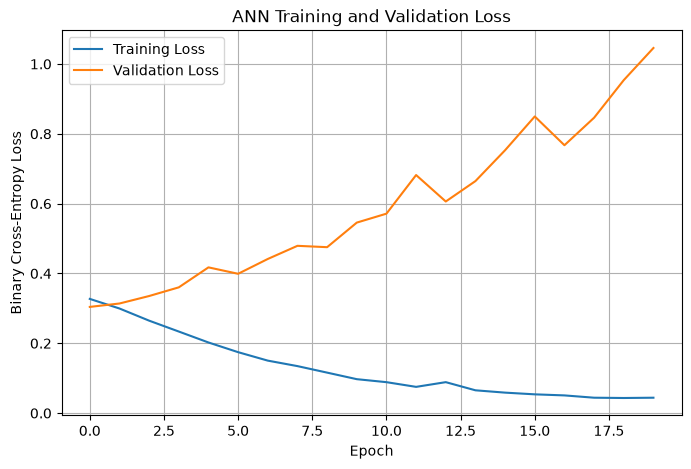

In [32]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("ANN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


In [33]:

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix
)

# Put ANN into evaluation mode
model.eval()

# Generate validation predictions
with torch.no_grad():
    val_logits = model(X_val)
    val_probs = torch.sigmoid(val_logits)

# Convert tensors into NumPy arrays
y_true = y_val.numpy().ravel()
y_prob = val_probs.numpy().ravel()

# Convert probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
auroc = roc_auc_score(y_true, y_prob)
auprc = average_precision_score(y_true, y_prob)
mcc = matthews_corrcoef(y_true, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUROC:    {auroc:.4f}")
print(f"AUPRC:    {auprc:.4f}")
print(f"MCC:      {mcc:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))


Accuracy: 0.7331
AUROC:    0.6560
AUPRC:    0.8601
MCC:      0.2285

Confusion matrix:
[[ 79 122]
 [115 572]]


In [34]:

# Create a new, smaller ANN
model_v2 = nn.Sequential(
    nn.Linear(960, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 16),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(16, 1)
)

# Define loss function
criterion_v2 = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([positive_weight])
)

# Define optimizer with weight decay
optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=0.0005,
    weight_decay=0.001
)

print(model_v2)


Sequential(
  (0): Linear(in_features=960, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=64, out_features=16, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=16, out_features=1, bias=True)
)


In [35]:

import copy

num_epochs = 20

train_losses_v2 = []
val_losses_v2 = []

best_val_loss_v2 = float("inf")
best_model_state_v2 = None
best_epoch_v2 = 0

for epoch in range(num_epochs):

    # 1. TRAINING
    model_v2.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        optimizer_v2.zero_grad()

        logits = model_v2(X_batch)

        loss = criterion_v2(logits, y_batch)

        loss.backward()

        optimizer_v2.step()

        total_train_loss += loss.item() * len(X_batch)

    avg_train_loss = total_train_loss / len(train_dataset)
    train_losses_v2.append(avg_train_loss)

    # 2. VALIDATION
    model_v2.eval()

    with torch.no_grad():
        val_logits = model_v2(X_val)
        val_loss = criterion_v2(val_logits, y_val)

    avg_val_loss = val_loss.item()
    val_losses_v2.append(avg_val_loss)

    # 3. SAVE BEST MODEL
    if avg_val_loss < best_val_loss_v2:
        best_val_loss_v2 = avg_val_loss
        best_epoch_v2 = epoch + 1
        best_model_state_v2 = copy.deepcopy(
            model_v2.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

# Restore the best model
model_v2.load_state_dict(best_model_state_v2)

print("\nBest epoch:", best_epoch_v2)
print("Best validation loss:", round(best_val_loss_v2, 4))


Epoch 01/20 | Train Loss: 0.3311 | Val Loss: 0.3196
Epoch 02/20 | Train Loss: 0.3227 | Val Loss: 0.3081
Epoch 03/20 | Train Loss: 0.3084 | Val Loss: 0.3049
Epoch 04/20 | Train Loss: 0.3005 | Val Loss: 0.2980
Epoch 05/20 | Train Loss: 0.2908 | Val Loss: 0.2996
Epoch 06/20 | Train Loss: 0.2830 | Val Loss: 0.2973
Epoch 07/20 | Train Loss: 0.2748 | Val Loss: 0.3069
Epoch 08/20 | Train Loss: 0.2637 | Val Loss: 0.3106
Epoch 09/20 | Train Loss: 0.2613 | Val Loss: 0.3135
Epoch 10/20 | Train Loss: 0.2500 | Val Loss: 0.3172
Epoch 11/20 | Train Loss: 0.2437 | Val Loss: 0.3181
Epoch 12/20 | Train Loss: 0.2345 | Val Loss: 0.3396
Epoch 13/20 | Train Loss: 0.2316 | Val Loss: 0.3302
Epoch 14/20 | Train Loss: 0.2198 | Val Loss: 0.3340
Epoch 15/20 | Train Loss: 0.2078 | Val Loss: 0.3513
Epoch 16/20 | Train Loss: 0.2077 | Val Loss: 0.3882
Epoch 17/20 | Train Loss: 0.1999 | Val Loss: 0.3675
Epoch 18/20 | Train Loss: 0.1937 | Val Loss: 0.3658
Epoch 19/20 | Train Loss: 0.1846 | Val Loss: 0.3777
Epoch 20/20 

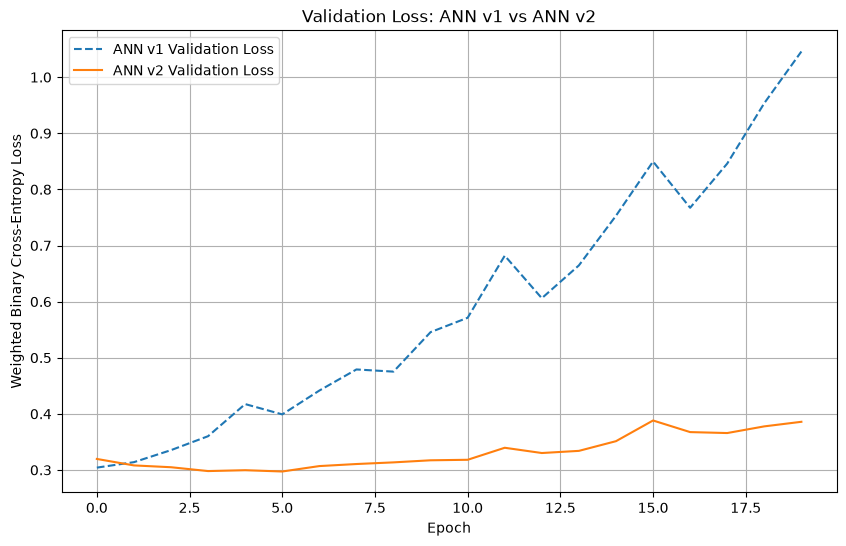

In [36]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Original ANN
plt.plot(
    val_losses,
    label="ANN v1 Validation Loss",
    linestyle="--"
)

# Regularized ANN
plt.plot(
    val_losses_v2,
    label="ANN v2 Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Weighted Binary Cross-Entropy Loss")
plt.title("Validation Loss: ANN v1 vs ANN v2")
plt.legend()
plt.grid(True)

plt.show()


In [37]:

# Evaluation mode
model_v2.eval()

# Generate validation predictions
with torch.no_grad():
    logits_v2 = model_v2(X_val)
    probs_v2 = torch.sigmoid(logits_v2)

# Convert predictions into NumPy arrays
y_true_v2 = y_val.numpy().ravel()
y_prob_v2 = probs_v2.numpy().ravel()

# Convert probabilities into binary labels
y_pred_v2 = (y_prob_v2 >= 0.5).astype(int)

# Calculate metrics
accuracy_v2 = accuracy_score(y_true_v2, y_pred_v2)
auroc_v2 = roc_auc_score(y_true_v2, y_prob_v2)
auprc_v2 = average_precision_score(y_true_v2, y_prob_v2)
mcc_v2 = matthews_corrcoef(y_true_v2, y_pred_v2)

print(f"Accuracy: {accuracy_v2:.4f}")
print(f"AUROC:    {auroc_v2:.4f}")
print(f"AUPRC:    {auprc_v2:.4f}")
print(f"MCC:      {mcc_v2:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_true_v2, y_pred_v2))


Accuracy: 0.7016
AUROC:    0.7046
AUPRC:    0.8845
MCC:      0.2558

Confusion matrix:
[[107  94]
 [171 516]]


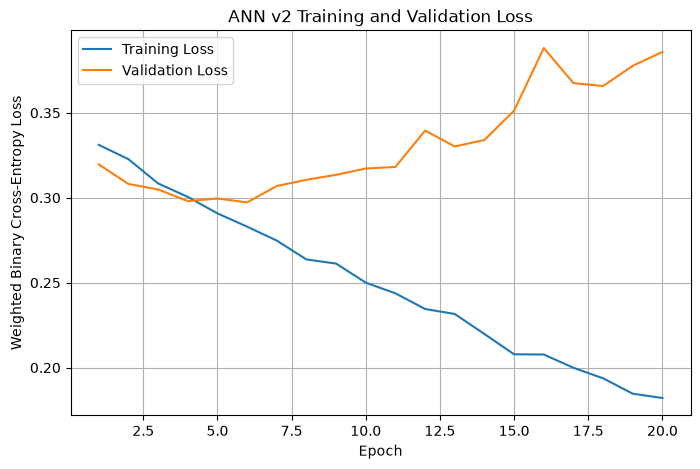

In [39]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses_v2,
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses_v2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Weighted Binary Cross-Entropy Loss")
plt.title("ANN v2 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


In [40]:

import numpy as np
from sklearn.metrics import matthews_corrcoef

# Candidate thresholds
thresholds = np.arange(0.1, 0.91, 0.01)

mcc_scores = []

for threshold in thresholds:

    # Convert model scores into class predictions
    predictions = (y_prob_v2 >= threshold).astype(int)

    # Calculate MCC
    mcc = matthews_corrcoef(y_true_v2, predictions)

    mcc_scores.append(mcc)

# Identify the threshold with the highest MCC
best_index = np.argmax(mcc_scores)

best_threshold = thresholds[best_index]
best_mcc = mcc_scores[best_index]

print(f"Best threshold: {best_threshold:.2f}")
print(f"Best validation MCC: {best_mcc:.4f}")


Best threshold: 0.42
Best validation MCC: 0.2862


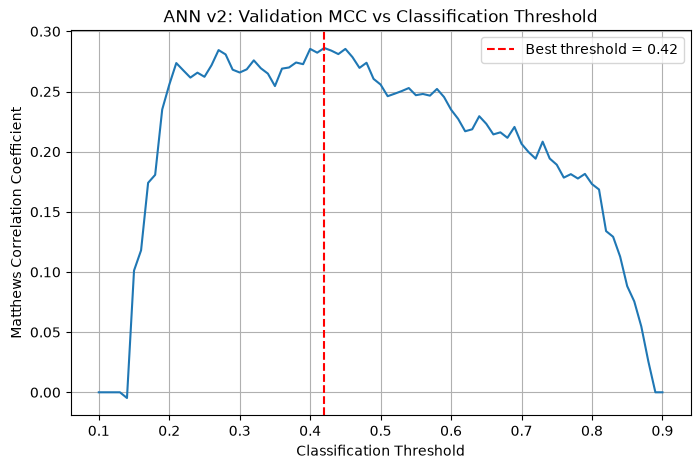

In [41]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(thresholds, mcc_scores)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Matthews Correlation Coefficient")
plt.title("ANN v2: Validation MCC vs Classification Threshold")

plt.legend()
plt.grid(True)
plt.show()


In [42]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    matthews_corrcoef
)

# Use the best threshold found on validation data
optimized_predictions = (
    y_prob_v2 >= best_threshold
).astype(int)

print("Threshold:", round(best_threshold, 2))

print(
    "Accuracy:",
    round(accuracy_score(y_true_v2, optimized_predictions), 4)
)

print(
    "Precision:",
    round(precision_score(y_true_v2, optimized_predictions), 4)
)

print(
    "Recall:",
    round(recall_score(y_true_v2, optimized_predictions), 4)
)

print(
    "MCC:",
    round(matthews_corrcoef(y_true_v2, optimized_predictions), 4)
)

print("\nConfusion matrix:")
print(confusion_matrix(y_true_v2, optimized_predictions))


Threshold: 0.42
Accuracy: 0.741
Precision: 0.8426
Recall: 0.818
MCC: 0.2862

Confusion matrix:
[[ 96 105]
 [125 562]]


In [43]:

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    confusion_matrix
)

# Set ANN v2 to evaluation mode
model_v2.eval()

# Generate predictions for the test dataset
with torch.no_grad():
    test_logits = model_v2(X_test)
    test_probs = torch.sigmoid(test_logits)

# Convert tensors to NumPy arrays
y_test_true = y_test.numpy().ravel()
y_test_prob = test_probs.numpy().ravel()

# Use the threshold selected on validation data
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

# Calculate test metrics
print("ANN v2 — TEST RESULTS")
print("---------------------")

print("Accuracy:",
      round(accuracy_score(y_test_true, y_test_pred), 4))

print("AUROC:",
      round(roc_auc_score(y_test_true, y_test_prob), 4))

print("AUPRC:",
      round(average_precision_score(y_test_true, y_test_prob), 4))

print("MCC:",
      round(matthews_corrcoef(y_test_true, y_test_pred), 4))

print("Precision:",
      round(precision_score(y_test_true, y_test_pred), 4))

print("Recall:",
      round(recall_score(y_test_true, y_test_pred), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_true, y_test_pred))


ANN v2 — TEST RESULTS
---------------------
Accuracy: 0.6479
AUROC: 0.6628
AUPRC: 0.813
MCC: 0.1024
Precision: 0.7143
Recall: 0.8159

Confusion matrix:
[[ 53 140]
 [ 79 350]]
